In [1]:
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from tree.xg_classifier import XGClassifier
from xgboost import XGBClassifier
import shap
from common.helper import load_data_and_scale_pos_weight
from mini_shap.independent_tree_shap import IndependentTreeExplainer

/home/sakane/Documents/projects/python/mini_xgshap/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
X_train, X_test, y_train, y_test, scale_pos_weight = load_data_and_scale_pos_weight(cast_string=True)
X_train_np, X_test_np, y_train_np, y_test_np = X_train.to_numpy().astype(np.float32), X_test.to_numpy().astype(np.float32), y_train.to_numpy().astype(np.float32), y_test.to_numpy().astype(np.float32)

In [3]:
m1 = XGBClassifier()
m1.load_model('../model/prauc_model2.ubj')
m2 = XGClassifier.load_from_xgbclassifier(m1, columns=list(X_train.columns))

In [4]:
pred_raw1 = m1.predict(X_test, output_margin=True)

In [5]:
# Get 1000 random samples from train set
indices = np.random.choice(len(X_train_np), 1000, replace=False)
background_sample = X_train_np[indices]
foreground_sample = X_test_np

In [6]:
expl = IndependentTreeExplainer(
    model=m2,
    refset=background_sample,
    model_output='raw',
)

shap_values = expl.full_vectorized_explain(foreground_sample)

In [7]:
explanation = shap.Explanation(
    values=shap_values,
    base_values=expl.expected_value,
    data=X_test_np,
    feature_names=X_train.columns,
)

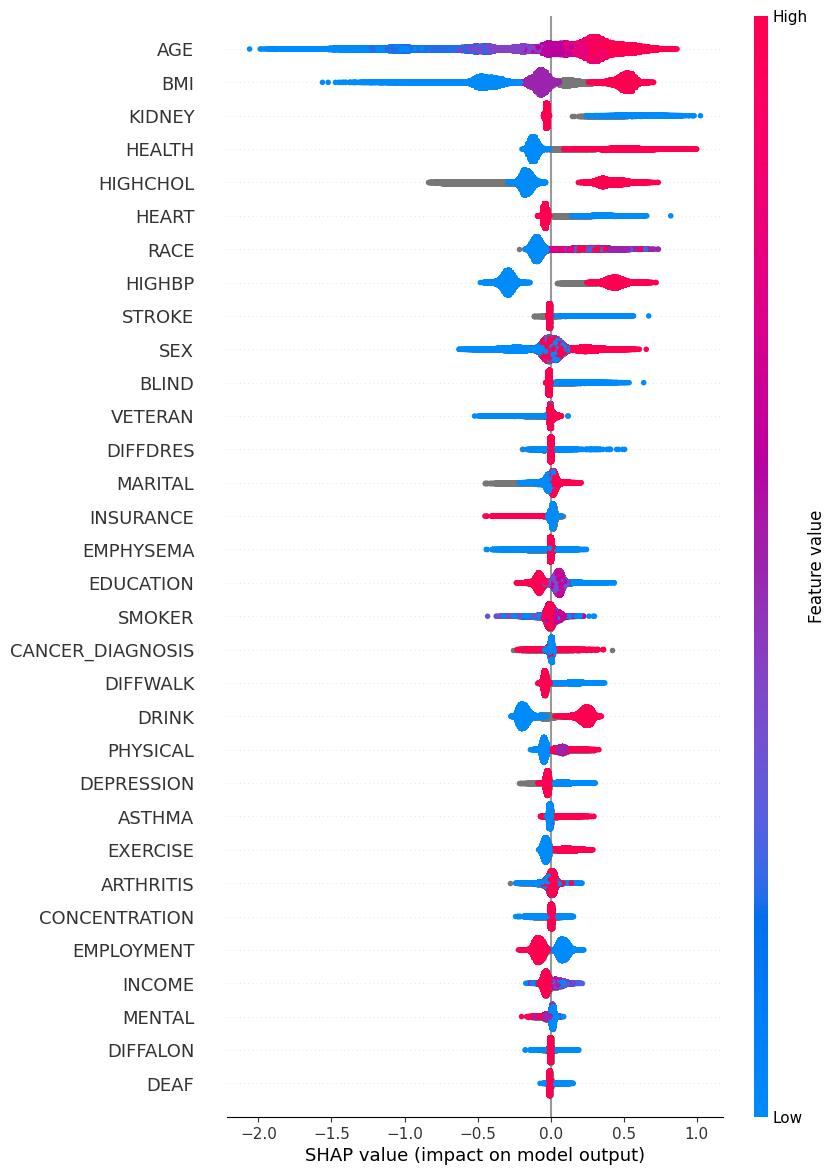

In [8]:
shap.plots.beeswarm(explanation, order=explanation.abs.max(0), max_display=33)

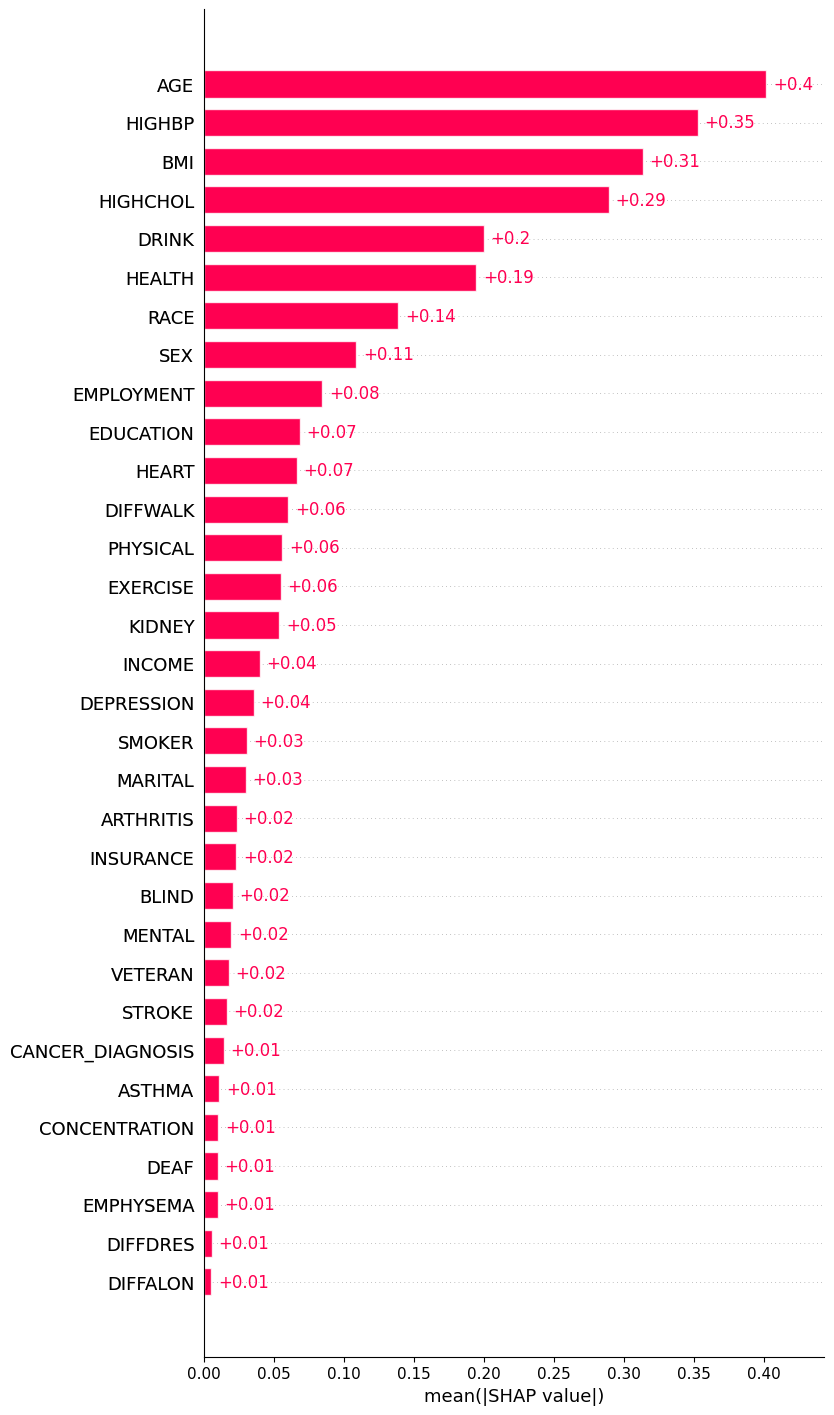

In [9]:
shap.plots.bar(explanation, max_display=33)

In [10]:
mask = np.isclose(pred_raw1, expl.expected_value + shap_values.sum(1), rtol=0.0, atol=1e-4)
mask.sum() == len(pred_raw1)

np.True_